Original Dataset:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

After Removing Duplicates:
(780, 8)

Statistical Analysis:
         survived      pclass         age       sibsp       parch        fare
count  780.000000  780.000000  676.000000  780.000000  780.0000

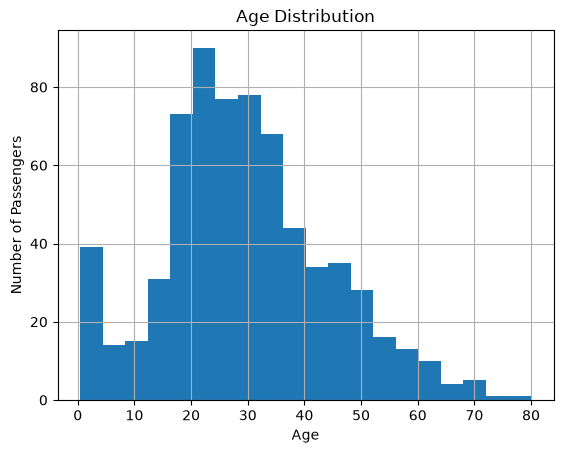

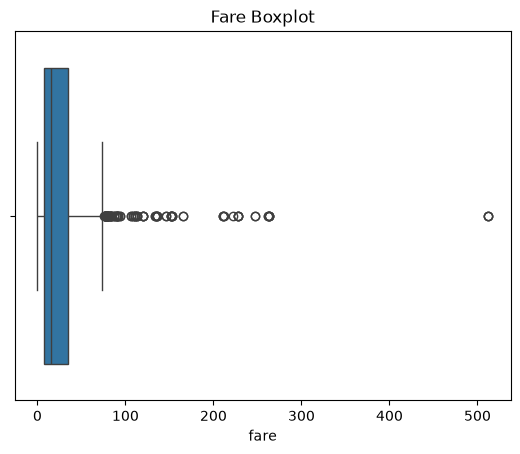


Training Data Shape: (624, 10)
Testing Data Shape: (156, 10)

Preprocessed Training Data:
     pclass       age  sibsp  parch      fare  sex_female  sex_male  \
710       1 -0.371904      0      0  0.393649           1         0   
830       3 -1.024306      1      0 -0.385409           1         0   
114       3 -0.879328      0      0 -0.385318           1         0   
652       3 -0.589371      0      0 -0.519236           0         1   
624       3 -0.589371      0      0 -0.348828           0         1   

     embarked_C  embarked_Q  embarked_S  
710           1           0           0  
830           1           0           0  
114           1           0           0  
652           0           0           1  
624           0           0           1  

Missing Values After Preprocessing:
pclass        0
age           0
sibsp         0
parch         0
fare          0
sex_female    0
sex_male      0
embarked_C    0
embarked_Q    0
embarked_S    0
dtype: int64

Preprocessing Compl

In [12]:

# 1. Import libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# 2. Download and Load Dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Original Dataset:")
print(df.head())


# 3. Select Required Columns

df = df[['survived', 'pclass', 'sex', 'age',
         'sibsp', 'parch', 'fare', 'embarked']]


# 4. Data Cleaning

# Remove duplicate rows

df = df.drop_duplicates()

print("\nAfter Removing Duplicates:")
print(df.shape)


# 5. Statistical Analysis

print("\nStatistical Analysis:")
print(df.describe())


# 6. Data Visualization

# Histogram

df['age'].hist(bins=20)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()


# Boxplot

sns.boxplot(x=df['fare'])

plt.title("Fare Boxplot")
plt.show()


# 7. Separate Input and Output

X = df.drop('survived', axis=1)

y = df['survived']


# 8. Split Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 9. Missing Value Handling

# Fill numerical missing values using training median

num_cols = ['age', 'fare']

for col in num_cols:

    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)

    X_test[col] = X_test[col].fillna(median_value)


# Fill categorical missing values using training mode

cat_cols = ['sex', 'embarked']

for col in cat_cols:

    mode_value = X_train[col].mode()[0]

    X_train[col] = X_train[col].fillna(mode_value)

    X_test[col] = X_test[col].fillna(mode_value)


# 10. Encoding Categorical Data

X_train = pd.get_dummies(
    X_train, columns=cat_cols, dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=cat_cols, dtype=int
)

# Keep the same columns in training and testing data

X_test = X_test.reindex(
    columns=X_train.columns, fill_value=0
)


# 11. Feature Scaling

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

X_test[num_cols] = scaler.transform(X_test[num_cols])


# 12. Final Output

print("\nTraining Data Shape:", X_train.shape)

print("Testing Data Shape:", X_test.shape)

print("\nPreprocessed Training Data:")

print(X_train.head())

print("\nMissing Values After Preprocessing:")

print(X_train.isnull().sum())

print("\nPreprocessing Completed Successfully!")

